In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/ai-impact-jobs-layoff-risk-dataset.csv")
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [3]:
print("Shape:", df.shape)
df.info()
df.isnull().sum()

Shape: (20000, 16)
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         20000 non-null  int64
 1   Education_Level             20000 non-null  str  
 2   Years_of_Experience         20000 non-null  int64
 3   Industry                    20000 non-null  str  
 4   Job_Role                    20000 non-null  str  
 5   Company_Size                20000 non-null  str  
 6   Job_Level                   20000 non-null  str  
 7   Routine_Task_Percentage     20000 non-null  int64
 8   Creativity_Requirement      20000 non-null  int64
 9   Human_Interaction_Level     20000 non-null  int64
 10  AI_Adoption_Level           20000 non-null  str  
 11  Number_of_AI_Tools_Used     20000 non-null  int64
 12  AI_Usage_Hours_Per_Week     20000 non-null  int64
 13  Tasks_Automated_Percentage  20000 non-null  int64
 14

Age                           0
Education_Level               0
Years_of_Experience           0
Industry                      0
Job_Role                      0
Company_Size                  0
Job_Level                     0
Routine_Task_Percentage       0
Creativity_Requirement        0
Human_Interaction_Level       0
AI_Adoption_Level             0
Number_of_AI_Tools_Used       0
AI_Usage_Hours_Per_Week       0
Tasks_Automated_Percentage    0
AI_Training_Hours             0
Layoff_Risk                   0
dtype: int64

In [4]:
cat_cols = [
    "Education_Level", "Industry", "Job_Role", "Company_Size",
    "Job_Level", "AI_Adoption_Level", "Layoff_Risk"
]

for col in cat_cols:
    print("\n", col)
    print(df[col].value_counts())


 Education_Level
Education_Level
Bachelor's     9967
Master's       5426
High School    3558
PhD            1049
Name: count, dtype: int64

 Industry
Industry
Telecom          2582
Healthcare       2561
Finance          2513
Logistics        2488
IT               2483
Retail           2467
Manufacturing    2457
Education        2449
Name: count, dtype: int64

 Job_Role
Job_Role
Nurse                    900
Medical Assistant        889
Financial Analyst        879
Support Specialist       873
Network Engineer         862
Operator                 858
Inventory Analyst        857
Supply Chain Analyst     857
Data Analyst             849
Operations Analyst       847
Warehouse Manager        843
Software Engineer        829
Accountant               821
Academic Coordinator     819
Research Assistant       818
Auditor                  813
Teacher                  812
Sales Associate          807
Production Supervisor    806
ML Engineer              805
Store Manager            803
Quality E

In [5]:
print(df["Job_Level"].value_counts())
print("\n")
print(df["AI_Adoption_Level"].value_counts())
print("\n")
print(df["Layoff_Risk"].value_counts())

Job_Level
Entry     9016
Mid       7940
Senior    3044
Name: count, dtype: int64


AI_Adoption_Level
Low       10539
Medium     8046
High       1415
Name: count, dtype: int64


Layoff_Risk
High      6797
Low       6602
Medium    6601
Name: count, dtype: int64


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

# Clustering-க்கு target வேண்டாம்
X = df.drop(columns=["Layoff_Risk"])
y = df["Layoff_Risk"]   # validation-க்கு மட்டும்

numeric_features = [
    "Age", "Years_of_Experience", "Routine_Task_Percentage",
    "Creativity_Requirement", "Human_Interaction_Level",
    "Number_of_AI_Tools_Used", "AI_Usage_Hours_Per_Week",
    "Tasks_Automated_Percentage", "AI_Training_Hours"
]

ordinal_features = ["Job_Level", "AI_Adoption_Level"]

onehot_features = [
    "Education_Level", "Industry", "Job_Role", "Company_Size"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("ord", OrdinalEncoder(
            categories=[
                ["Entry", "Mid", "Senior"],
                ["Low", "Medium", "High"]
            ]
        ), ordinal_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), onehot_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)

Original shape: (20000, 15)
Processed shape: (20000, 50)


K=2 | Inertia=189601.44 | Silhouette=0.2337
K=3 | Inertia=169948.31 | Silhouette=0.2109
K=4 | Inertia=159743.63 | Silhouette=0.1385
K=5 | Inertia=152274.80 | Silhouette=0.1050
K=6 | Inertia=146932.69 | Silhouette=0.0992
K=7 | Inertia=142939.29 | Silhouette=0.0940
K=8 | Inertia=139421.10 | Silhouette=0.0914


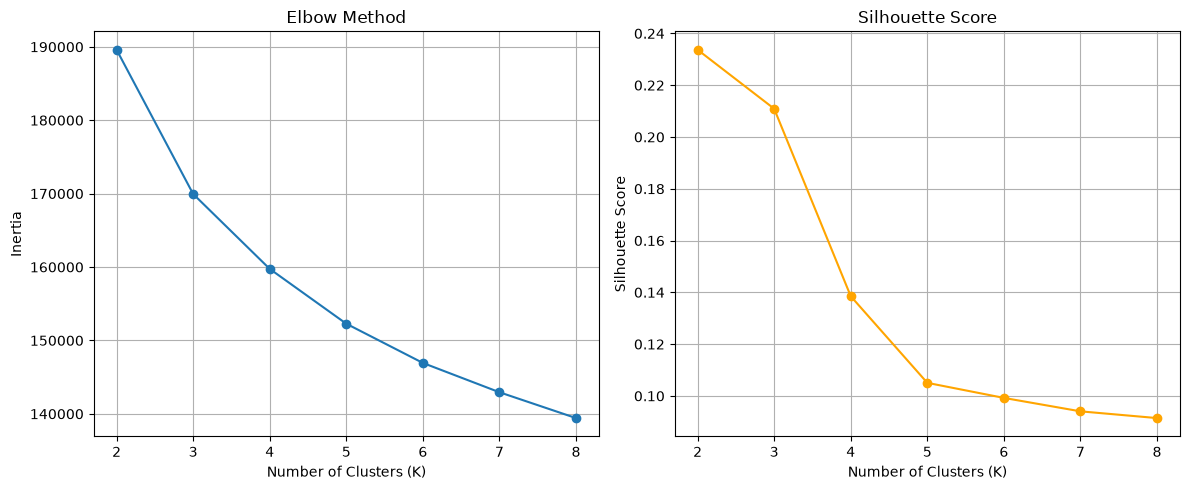

Best K based on Silhouette Score: 2


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia_values = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_processed)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_processed, labels))
    
    print(f"K={k} | Inertia={kmeans.inertia_:.2f} | Silhouette={silhouette_scores[-1]:.4f}")

# Elbow plot
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_scores, marker="o", color="orange")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.grid(True)

plt.tight_layout()
plt.show()

best_k = k_values[silhouette_scores.index(max(silhouette_scores))]
print("Best K based on Silhouette Score:", best_k)